# ¿Qué tan grande se vuelve el brote? El tamaño final y por qué ignora el tiempo

**Pregunta:** ¿Qué parte de una población infecta un brote al final, por qué esa parte depende de $R_0$ y no de qué tan rápido corre el brote, y cuándo la corrida del propio motor no la alcanza?

- **Nivel:** 2, El método en la práctica
- **Requisitos:** notebook 01 de este tema
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes resolver la relación del tamaño final por iteración y ver cómo converge, ubicar las tasas de ataque que simula el motor sobre la curva de la relación, mostrar que dos brotes con el mismo $R_0$ y distinta velocidad terminan en el mismo tamaño, y decir cómo cambian la respuesta los primeros infectados y el largo del horizonte.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

Si se divide la ecuación de $S$ por la de $R$ en el sistema SIR, el tiempo se cancela y $dS/dR = -(\beta / \gamma) S / N$, que integra a $S = S_0 \, e^{-R_0 R / N}$. Cuando el brote ha terminado no queda nadie infectado, de modo que $S_\infty = N - R_\infty$ y la parte alguna vez infectada $z = R_\infty / N$ cumple

$$1 - z = (1 - i_0)\, e^{-R_0 z}$$

con $i_0 = I_0 / N$ (Kermack y McKendrick, 1927; Miller, 2012). La tasa de contacto y la de recuperación aparecen solo por su cociente y el tiempo no aparece. Para $i_0 \to 0$ y $R_0 \le 1$ la única solución es $z = 0$. La función `final_size` de `data-pipeline/pipeline/oracles.py` la resuelve por iteración de punto fijo: parte de $z = 1$ y repite $z \leftarrow 1 - (1 - i_0) e^{-R_0 z}$ hasta que dos valores consecutivos difieren en menos de $10^{-12}$. No comparte código con el motor, así que un desacuerdo entre los dos dice algo sobre uno de ellos.

Primero la iteración misma, para el caso epidémico, $R_0 = 2{,}75$. La celda guarda cada iterada e imprime las seis primeras, el número de iteraciones y la solución. La iteración parte de la peor suposición, todos infectados, de modo que las primeras iteradas bajan hacia la respuesta.

In [2]:
# resuelve la relación del tamaño final del caso epidémico por punto fijo y guarda cada iterada
r0 = 2.75
iterates = []
z = final_size(r0, trace=iterates)
print("primeras iteraciones", [round(float(v), 5) for v in iterates[:6]])
print(f"iteraciones: {len(iterates)}, z = {z:.6f}")

primeras iteraciones [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044]
iteraciones: 18, z = 0.920437


Las iteradas 0,93607, 0,92379 y 0,92117 se asientan en 0,92044 en seis pasos, y el lazo se detiene tras 18 cuando el cambio es menor que la tolerancia. Una solución tan rápida no está garantizada con cualquier $R_0$: la celda siguiente repite la iteración para cuatro valores, desde un 1,2 apenas supercrítico hasta un violento 6,0, y cuenta las iteraciones que necesita cada uno.

In [3]:
# la misma iteración con cuatro valores de R0, para ver cuántos pasos necesita cada uno
traces = {}
for value in (1.2, 1.5, 2.75, 6.0):
    traces[value] = []
    final_size(value, trace=traces[value])
    print(f"R0 = {value:4.2f}  z = {traces[value][-1]:.4f}  {len(traces[value]):4d} iteraciones")

R0 = 1.20  z = 0.3137   127 iteraciones
R0 = 1.50  z = 0.5828    55 iteraciones
R0 = 2.75  z = 0.9204    18 iteraciones
R0 = 6.00  z = 0.9975     7 iteraciones


La celda siguiente dibuja las iteradas contra el número de iteración para los cuatro valores de $R_0$.

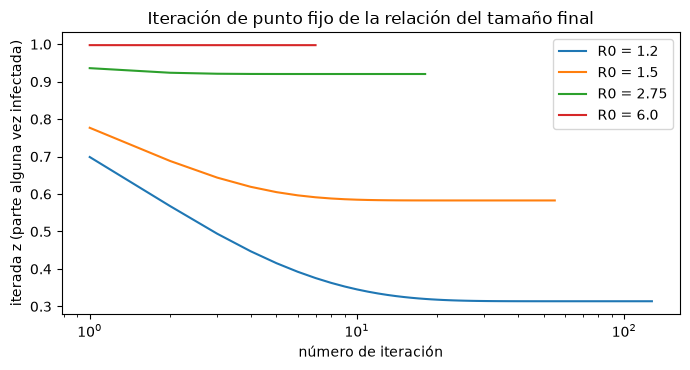

In [4]:
# dibuja las iteradas contra el número de iteración para los cuatro valores de R0
fig, ax = plt.subplots(figsize=(7, 3.8))
for value, trace in traces.items():
    ax.plot(range(1, len(trace) + 1), trace, label=f"R0 = {value}")
ax.set_xscale("log")
ax.set_xlabel("número de iteración")
ax.set_ylabel("iterada z (parte alguna vez infectada)")
ax.set_title("Iteración de punto fijo de la relación del tamaño final")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva es una iteración, y todas bajan desde 1 hacia su propia respuesta. Para $R_0 = 6$ termina en 7 pasos; para $R_0 = 1{,}2$ toma 127, porque cerca del umbral la función $z \mapsto 1 - e^{-R_0 z}$ es casi tangente a la diagonal y las iteradas avanzan reptando. La figura usa un eje logarítmico para el número de iteración y así se ven ambos extremos. Todavía no dice nada del motor; la celda siguiente lo incorpora calculando la relación sobre una malla de $R_0$ y simulando cada caso con personas infectadas.

In [5]:
# la curva del tamaño final sobre R0, y la tasa de ataque que el motor simula en cada caso con infectados
grid = np.linspace(0.5, 6.5, 121)
curve = [final_size(g) for g in grid]
points = {}
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    r0_case = p.beta / p.gamma
    points[case_id] = (r0_case, simulate(p).attack_rate)
    print(f"{case_id:18s} R0 = {r0_case:4.2f}  z = {final_size(r0_case, p.I0 / p.N):.4f}", end="  ")
    print(f"simulada {points[case_id][1]:.4f}")

EX01_subcritical   R0 = 0.72  z = 0.0018  simulada 0.0018
EX02_epidemic      R0 = 2.75  z = 0.9205  simulada 0.9237
EX03_fast_burn     R0 = 6.00  z = 0.9975  simulada 0.9982
EX04_slow_spread   R0 = 1.20  z = 0.3156  simulada 0.2993


La celda siguiente dibuja la curva de la relación y ubica cada caso en ella según su $R_0$ y su tasa de ataque simulada.

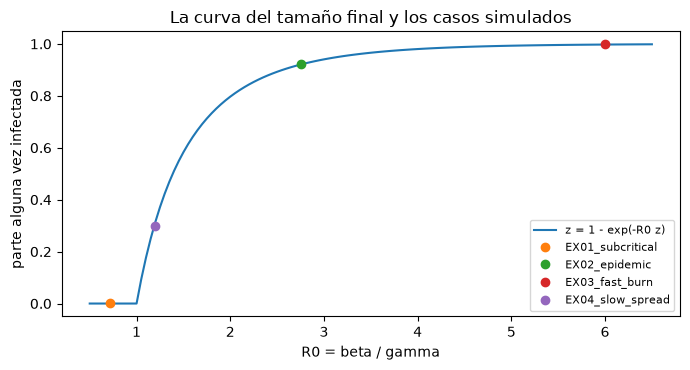

In [6]:
# dibuja la curva de la relación y ubica cada caso según su R0 y su tasa de ataque simulada
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, curve, label="z = 1 - exp(-R0 z)")
for case_id, (r0_case, attack) in points.items():
    ax.plot([r0_case], [attack], "o", label=case_id)
ax.set_xlabel("R0 = beta / gamma")
ax.set_ylabel("parte alguna vez infectada")
ax.set_title("La curva del tamaño final y los casos simulados")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva vale cero hasta $R_0 = 1$, sube con fuerza hasta 0,5828 en $R_0 = 1{,}5$ y se aplana contra 1 para $R_0$ grande: ningún brote infecta a todos, y los últimos puntos porcentuales cuestan. Los casos del motor se ubican sobre ella. El epidémico y la combustión rápida quedan 0,0032 y 0,0007 sobre la relación, que es la aritmética de Euler medida en el notebook 02 del tema 01; el subcrítico queda en 0,0018, las infecciones iniciales y casi nadie más. La propagación lenta es la excepción, 0,2993 frente a 0,3156. La figura no puede decir por qué, y la celda del horizonte más abajo sí.

Ahora la afirmación de que el tiempo no importa. La celda corre el caso epidémico y un gemelo cuyas tasas de contacto y de recuperación se duplican, de modo que el brote corre al doble de velocidad y $R_0$ sigue siendo 2,75. Si la relación es correcta, el pico debería llegar casi el doble de temprano y las tasas de ataque deberían ser casi iguales.

In [7]:
# el caso epidémico y un gemelo al doble de velocidad, con el mismo R0 = 2,75
base = params_of("EX02_epidemic")
twin = replace(base, beta=2 * base.beta, gamma=2 * base.gamma)
runs = {"EX02_epidemic": simulate(base), "el doble de rápido": simulate(twin)}
for label, r in runs.items():
    print(f"{label:16s} pico {r.peak_I:7.0f}  el día {r.t_peak:6.2f}  tasa de ataque {r.attack_rate:.4f}")

EX02_epidemic    pico   27345  el día  24.25  tasa de ataque 0.9237
el doble de rápido pico   27836  el día  12.50  tasa de ataque 0.9269


La celda siguiente dibuja las personas infectadas de las dos corridas sobre los mismos ejes.

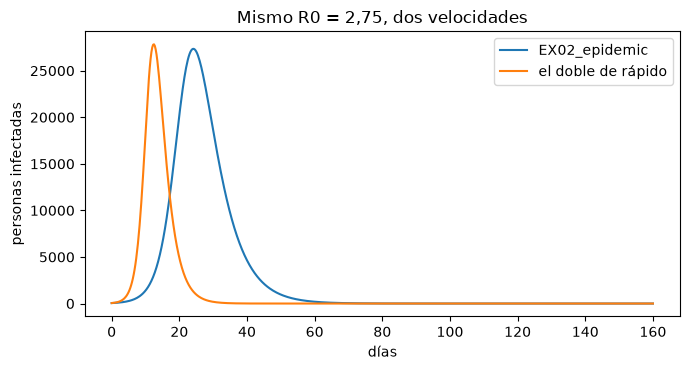

In [8]:
# dibuja las personas infectadas de las dos corridas sobre los mismos ejes
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, r in runs.items():
    ax.plot(r.t, r.I, label=label)
ax.set_xlabel("días")
ax.set_ylabel("personas infectadas")
ax.set_title("Mismo R0 = 2,75, dos velocidades")
ax.legend()
fig.tight_layout()
plt.show()

El gemelo alcanza su máximo el día 12,50 en lugar del día 24,25, la mitad del tiempo, y su curva es la misma joroba comprimida en el tiempo, pero ambos brotes terminan con casi la misma parte infectada, 0,9237 y 0,9269. El tamaño final es una propiedad de $R_0$ y el curso en el tiempo es una propiedad de las tasas. La diferencia de 0,0032 entre las dos tasas de ataque no es física: es otra vez el error de Euler, mayor para el gemelo rápido porque un cuarto de día cubre más de su curso. La figura muestra la compresión; no muestra la pequeña diferencia.

La relación tiene un segundo argumento, la parte inicial de infectados $i_0$, que las celdas anteriores dejaron en cero. La celda siguiente sube los primeros infectados a 5000 y a 20000 y compara tres números: la relación con $i_0$, la relación sin él, y el motor.

In [9]:
# sube los primeros infectados a 5000 y a 20000: la relación sigue al motor cuando se le da i0
for first in (50, 5000, 20000):
    q = replace(base, I0=first)
    z_i0 = final_size(2.75, first / base.N)
    print(f"I0 = {first:6d}  z(R0, i0) = {z_i0:.4f}  z(R0) = {final_size(2.75):.4f}", end="  ")
    print(f"simulada {simulate(q).attack_rate:.4f}")

I0 =     50  z(R0, i0) = 0.9205  z(R0) = 0.9204  simulada 0.9237
I0 =   5000  z(R0, i0) = 0.9254  z(R0) = 0.9204  simulada 0.9287
I0 =  20000  z(R0, i0) = 0.9396  z(R0) = 0.9204  simulada 0.9428


Con 20000 personas infectadas al inicio, una quinta parte del pueblo, la relación sin $i_0$ se equivoca en 0,019, mientras que la relación con $i_0$ queda a 0,0033 del motor en las tres filas. Esa diferencia constante es de nuevo el error de Euler, y dice que la relación, con su segundo argumento, describe lo que hace el motor. El último caso es la propagación lenta, cuya tasa de ataque quedó corta frente a la relación. La celda lo corre con su horizonte propio de 160 días y con 300 días.

In [10]:
# el caso de propagación lenta con su horizonte de 160 días y con 300 días, frente a la relación
slow = params_of("EX04_slow_spread")
z_slow = final_size(slow.beta / slow.gamma, slow.I0 / slow.N)
for horizon in (160, 300):
    r = simulate(replace(slow, days=horizon))
    print(f"horizonte = {horizon:3d}  tasa de ataque {r.attack_rate:.4f}  z = {z_slow:.4f}")

horizonte = 160  tasa de ataque 0.2993  z = 0.3156
horizonte = 300  tasa de ataque 0.3162  z = 0.3156


## Resultados

**Respuesta:** Un brote con $R_0 = 2{,}75$ y 50 primeros casos en 100000 personas termina con 0,9205 de la población infectada según la relación, y la corrida de 160 días del motor da 0,9237, 0,0032 más, el error de Euler. La parte depende de $R_0$ y no de la velocidad: el brote gemelo que corre al doble de velocidad alcanza su máximo el día 12,50 en lugar del día 24,25 y aun así termina en 0,9269. Los infectados iniciales importan poco, de 0,9205 con 50 a 0,9254 con 5000 y 0,9396 con 20000, y la relación sigue al motor a menos de 0,0033 en todos. El motor no alcanza la relación cuando el brote no ha terminado en el horizonte: la propagación lenta, con $R_0 = 1{,}20$, ha infectado 0,2993 al día 160 frente a 0,3156 predicho, y llega a 0,3162 al día 300.

La relación describe el final de un brote en una población cerrada y bien mezclada y no dice nada sobre cuándo termina; es una cota, no un pronóstico para cualquier horizonte. Cerca del umbral además es lenta de calcular, 127 iteraciones con $R_0 = 1{,}2$, y el motor necesita un horizonte largo para confirmarla.

## Resumen

- El tamaño final $z$ resuelve $1 - z = (1 - i_0) e^{-R_0 z}$ y se encuentra con una iteración de punto fijo corta, lenta solo cerca del umbral.
- Depende de $R_0$ y de la parte inicial de infectados, no de la velocidad del brote: un gemelo al doble de las tasas alcanza su máximo al doble de temprano y termina en el mismo tamaño.
- El motor queda unos 0,003 sobre la relación, su error de Euler, donde el brote ha terminado dentro del horizonte.
- La propagación lenta no ha terminado al día 160, y la relación describe su final recién al día 300.
- Siguiente: los mismos casos frente a un resolvedor de orden mayor, en el notebook 03 del tema 01.

## Referencias

- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor y el oráculo de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`).